# 11. Консервативна LSTM з q20

**Етап 11 з 13** · NASA C-MAPSS FD001 · RUL prediction

## 1. Google Drive, imports and configuration

In [1]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [2]:
import copy
import json
import os
import random
import re
import zipfile
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler
from torch.utils.data import DataLoader, Dataset


DATA_DIR = Path(os.environ.get('FD001_DIR', '/content/drive/MyDrive/predictive_maintenance'))
OUT_DIR = Path(os.environ.get('FD001_OUT', 'outputs'))
OUT_DIR.mkdir(parents=True, exist_ok=True)

SEED = 42
WINDOW_SIZE = 80
HIDDEN_SIZE = 64
QUANTILE = 0.20
MAX_EPOCHS = 60
PATIENCE = 10
BATCH_SIZE = 128
LEARNING_RATE = 1e-3
NUM_WORKERS = 2
RUL_CAP_FOR_REPORT = 125
BASELINE_CYCLES = 20
DETECTOR_WINDOW = 10

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
PIN_MEMORY = DEVICE.type == 'cuda'


def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


set_seed()
print('Device:', DEVICE)
print('Data:', DATA_DIR)
print('Output:', OUT_DIR.resolve())


Device: cuda
Data: /content/drive/MyDrive/predictive_maintenance
Output: /content/outputs


### MLflow: логування саме моделей


In [ ]:
MLFLOW_TRACKING_URI = os.environ.get("MLFLOW_TRACKING_URI", "").strip()
MLFLOW_EXPERIMENT = os.environ.get(
    "MLFLOW_EXPERIMENT", "Predictive Maintenance - Conservative LSTM"
)


def _mlflow_metric_name(name):
    return re.sub(r"[^a-z0-9_]+", "_", name.lower()).strip("_")


def log_torch_model_to_mlflow(model, run_name, params, metrics, model_name="model"):
    """Log a complete PyTorch model plus reproducibility metadata; no-op when URI is empty."""
    if not MLFLOW_TRACKING_URI:
        print("MLflow skipped: set MLFLOW_TRACKING_URI to enable remote logging.")
        return None

    try:
        import mlflow
        import mlflow.pytorch
    except ImportError as exc:
        raise RuntimeError("Install MLflow first: %pip install -q mlflow") from exc

    mlflow.set_tracking_uri(MLFLOW_TRACKING_URI)
    mlflow.set_experiment(MLFLOW_EXPERIMENT)
    serializable_metrics = {
        _mlflow_metric_name(key): float(value)
        for key, value in metrics.items()
        if np.isscalar(value) and np.isfinite(value)
    }
    model_for_log = copy.deepcopy(model).cpu().eval()

    with mlflow.start_run(run_name=run_name) as run:
        mlflow.log_params(params)
        mlflow.log_metrics(serializable_metrics)
        mlflow.log_dict(
            {"features": list(FEATURE_COLUMNS)}, "reproducibility/feature_columns.json"
        )
        try:
            mlflow.pytorch.log_model(model_for_log, name=model_name)
        except TypeError:  # MLflow < 3
            mlflow.pytorch.log_model(model_for_log, artifact_path=model_name)
        print("MLflow run:", run.info.run_id)
        return run.info.run_id


## 2. Load FD001 and reproduce the engine-level split

In [3]:
COLUMNS = (
    ['unit_id', 'cycle', 'setting_1', 'setting_2', 'setting_3']
    + [f'sensor_{i}' for i in range(1, 22)]
)


def load_fd001(data_dir):
    paths = {
        'train': data_dir / 'train_FD001.txt',
        'test': data_dir / 'test_FD001.txt',
        'rul': data_dir / 'RUL_FD001.txt',
    }
    missing = [str(path) for path in paths.values() if not path.exists()]
    if missing:
        raise FileNotFoundError('Missing FD001 files:\n' + '\n'.join(missing))

    train = pd.read_csv(paths['train'], sep=r'\s+', header=None, names=COLUMNS)
    test = pd.read_csv(paths['test'], sep=r'\s+', header=None, names=COLUMNS)
    rul = pd.read_csv(paths['rul'], sep=r'\s+', header=None)[0].to_numpy(float)

    train = train.sort_values(['unit_id', 'cycle']).reset_index(drop=True)
    test = test.sort_values(['unit_id', 'cycle']).reset_index(drop=True)
    train['RUL'] = train.groupby('unit_id')['cycle'].transform('max') - train['cycle']

    if len(rul) != test['unit_id'].nunique():
        raise ValueError('RUL_FD001 count does not match test engines.')
    return train, test, rul


train_full, test_full, y_test_true = load_fd001(DATA_DIR)

splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
train_idx, val_idx = next(splitter.split(train_full, groups=train_full['unit_id']))
train_raw = train_full.iloc[train_idx].copy()
val_raw = train_full.iloc[val_idx].copy()

print('Train:', train_raw.shape, 'engines:', train_raw.unit_id.nunique())
print('Validation:', val_raw.shape, 'engines:', val_raw.unit_id.nunique())
print('Official test:', test_full.shape, 'engines:', test_full.unit_id.nunique())


Train: (16561, 27) engines: 80
Validation: (4070, 27) engines: 20
Official test: (13096, 26) engines: 100


## 3. Self-contained feature engineering and scaling


In [4]:
BASE_FEATURES = (
    ['cycle', 'setting_1', 'setting_2', 'setting_3']
    + [f'sensor_{i}' for i in range(1, 22)]
)
DEGRADATION_SENSORS = {
    'sensor_4': 1,
    'sensor_7': -1,
    'sensor_11': 1,
    'sensor_12': -1,
    'sensor_15': 1,
    'sensor_20': -1,
    'sensor_21': -1,
}
FEATURE_COLUMNS = BASE_FEATURES + ['degradation_score', 'degradation_warmup']


class DegradationScore:
    def __init__(self, baseline_cycles=20, window=10, directions=None):
        self.baseline_cycles = baseline_cycles
        self.window = window
        self.directions = directions or DEGRADATION_SENSORS
        self.sensors = list(self.directions)
        self.direction = pd.Series(self.directions, dtype=float)
        self.scale_ = None

    def fit(self, df):
        residuals = []
        for _, engine in df.sort_values('cycle').groupby('unit_id', sort=False):
            calibration = engine[self.sensors].iloc[:self.baseline_cycles]
            residuals.append(calibration - calibration.median())
        residuals = pd.concat(residuals, ignore_index=True)
        self.scale_ = residuals.abs().median().mul(1.4826).clip(lower=1e-6)
        return self

    def transform(self, df):
        if self.scale_ is None:
            raise RuntimeError('DegradationScore must be fitted first.')
        result = pd.Series(np.nan, index=df.index, dtype=float)
        for _, engine in df.groupby('unit_id', sort=False):
            engine = engine.sort_values('cycle')
            baseline = engine[self.sensors].iloc[:self.baseline_cycles].median()
            deviation = engine[self.sensors].sub(baseline).div(self.scale_)
            directional = deviation.mul(self.direction).clip(lower=0)
            score = directional.mean(axis=1).rolling(
                self.window, min_periods=1
            ).mean()
            score.iloc[:self.baseline_cycles] = np.nan
            result.loc[engine.index] = score.to_numpy()
        return result

    def to_dict(self):
        return {
            'baseline_cycles': self.baseline_cycles,
            'window': self.window,
            'directions': self.directions,
            'scale': {key: float(value) for key, value in self.scale_.items()},
        }


def add_features(df, detector):
    result = df.copy()
    result['degradation_score'] = detector.transform(result)
    result['degradation_warmup'] = result['degradation_score'].isna().astype('float32')
    return result


def fit_preprocessor(train_df):
    detector = DegradationScore(
        baseline_cycles=BASELINE_CYCLES,
        window=DETECTOR_WINDOW,
    ).fit(train_df)
    featured = add_features(train_df, detector)
    scaler = StandardScaler()
    scaler.fit(featured[FEATURE_COLUMNS].fillna(0).to_numpy(np.float64))
    return detector, scaler


def transform_data(df, detector, scaler):
    result = add_features(df, detector)
    result[FEATURE_COLUMNS] = scaler.transform(
        result[FEATURE_COLUMNS].fillna(0).to_numpy(np.float64)
    )
    return result


detector_split, scaler_split = fit_preprocessor(train_raw)
train_scaled = transform_data(train_raw, detector_split, scaler_split)
val_scaled = transform_data(val_raw, detector_split, scaler_split)

print('Model input size:', len(FEATURE_COLUMNS))
print(FEATURE_COLUMNS)


Model input size: 27
['cycle', 'setting_1', 'setting_2', 'setting_3', 'sensor_1', 'sensor_2', 'sensor_3', 'sensor_4', 'sensor_5', 'sensor_6', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_10', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_16', 'sensor_17', 'sensor_18', 'sensor_19', 'sensor_20', 'sensor_21', 'degradation_score', 'degradation_warmup']


## 4. Partial-history dataset

Кожен префікс двигуна — окремий training example. Історії коротші за 80 циклів доповнюються зліва першим рядком. Через ознаку `cycle` модель бачить фактичний поточний цикл.

In [5]:
class PartialHistoryDataset(Dataset):
    def __init__(self, df, feature_columns, window_size=80):
        if 'RUL' not in df.columns:
            raise ValueError('RUL column is required for training.')
        self.window_size = window_size
        self.engines = []
        self.index = []
        for _, engine in df.groupby('unit_id', sort=True):
            engine = engine.sort_values('cycle')
            engine_index = len(self.engines)
            features = engine[feature_columns].to_numpy(dtype=np.float32)
            targets = engine['RUL'].to_numpy(dtype=np.float32)
            self.engines.append((features, targets))
            self.index.extend((engine_index, end) for end in range(1, len(engine) + 1))

    def __len__(self):
        return len(self.index)

    def __getitem__(self, item):
        engine_index, end = self.index[item]
        features, targets = self.engines[engine_index]
        window = features[max(0, end - self.window_size):end]
        if len(window) < self.window_size:
            padding = np.repeat(window[:1], self.window_size - len(window), axis=0)
            window = np.vstack([padding, window])
        return torch.from_numpy(window.copy()), torch.tensor(targets[end - 1])


def make_last_windows(df, feature_columns, window_size=80):
    windows = []
    unit_ids = []
    for unit_id, engine in df.groupby('unit_id', sort=True):
        engine = engine.sort_values('cycle')
        features = engine[feature_columns].to_numpy(dtype=np.float32)
        if len(features) < window_size:
            padding = np.repeat(features[:1], window_size - len(features), axis=0)
            features = np.vstack([padding, features])
        windows.append(features[-window_size:])
        unit_ids.append(int(unit_id))
    return np.asarray(unit_ids), np.asarray(windows, dtype=np.float32)


def make_loader(dataset, shuffle, seed=SEED):
    generator = torch.Generator().manual_seed(seed)
    return DataLoader(
        dataset,
        batch_size=BATCH_SIZE,
        shuffle=shuffle,
        num_workers=NUM_WORKERS,
        pin_memory=PIN_MEMORY,
        persistent_workers=NUM_WORKERS > 0,
        generator=generator,
    )


train_dataset = PartialHistoryDataset(train_scaled, FEATURE_COLUMNS, WINDOW_SIZE)
val_dataset = PartialHistoryDataset(val_scaled, FEATURE_COLUMNS, WINDOW_SIZE)
train_loader = make_loader(train_dataset, shuffle=True)
val_loader = make_loader(val_dataset, shuffle=False)
print('Training windows:', len(train_dataset))
print('Validation windows:', len(val_dataset))


Training windows: 16561
Validation windows: 4070


## 5. Conservative LSTM and quantile loss

Для `q=0.20` overestimation отримує більшу вагу, ніж underestimation. Модель оцінює нижній умовний квантиль RUL, а не просто віднімає константу.

In [6]:
class RULLSTM(nn.Module):
    def __init__(self, in_features, hidden_size=64):
        super().__init__()
        self.lstm = nn.LSTM(
            in_features, hidden_size, num_layers=1, batch_first=True
        )
        self.fc = nn.Linear(hidden_size, 1)

    def forward(self, x):
        _, (hidden, _) = self.lstm(x)
        return self.fc(hidden[-1]).squeeze(-1)


class QuantileLoss(nn.Module):
    def __init__(self, quantile=0.20):
        super().__init__()
        self.quantile = quantile

    def forward(self, prediction, target):
        error = target - prediction
        return torch.maximum(
            self.quantile * error,
            (self.quantile - 1) * error,
        ).mean()


def run_epoch(model, loader, loss_fn, optimizer=None):
    training = optimizer is not None
    model.train(training)
    total_loss = 0.0
    total_items = 0
    context = torch.enable_grad() if training else torch.inference_mode()
    with context:
        for X, y in loader:
            X = X.to(DEVICE, non_blocking=True)
            y = y.to(DEVICE, non_blocking=True)
            prediction = model(X)
            loss = loss_fn(prediction, y)
            if training:
                optimizer.zero_grad(set_to_none=True)
                loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), 5.0)
                optimizer.step()
            total_loss += loss.item() * len(X)
            total_items += len(X)
    return total_loss / total_items


## 6. Select epoch count on validation engines

Epoch 001 | train=20.3731 | val=18.4951 | best=18.4951
Epoch 002 | train=18.2202 | val=16.8279 | best=16.8279
Epoch 003 | train=16.6601 | val=15.3856 | best=15.3856
Epoch 004 | train=15.2807 | val=14.1422 | best=14.1422
Epoch 005 | train=14.0826 | val=13.1193 | best=13.1193
Epoch 006 | train=13.0398 | val=12.0817 | best=12.0817
Epoch 007 | train=12.1584 | val=11.3048 | best=11.3048
Epoch 008 | train=11.4454 | val=10.6365 | best=10.6365
Epoch 009 | train=10.7953 | val=10.0327 | best=10.0327
Epoch 010 | train=10.3069 | val=9.6134 | best=9.6134
Epoch 011 | train=9.8557 | val=9.2545 | best=9.2545
Epoch 012 | train=9.4716 | val=8.9254 | best=8.9254
Epoch 013 | train=9.1438 | val=8.6271 | best=8.6271
Epoch 014 | train=8.8227 | val=8.2942 | best=8.2942
Epoch 015 | train=8.5685 | val=7.9627 | best=7.9627
Epoch 016 | train=8.2947 | val=7.7281 | best=7.7281
Epoch 017 | train=7.9487 | val=7.4646 | best=7.4646
Epoch 018 | train=7.6702 | val=7.2096 | best=7.2096
Epoch 019 | train=7.4475 | val=7.076

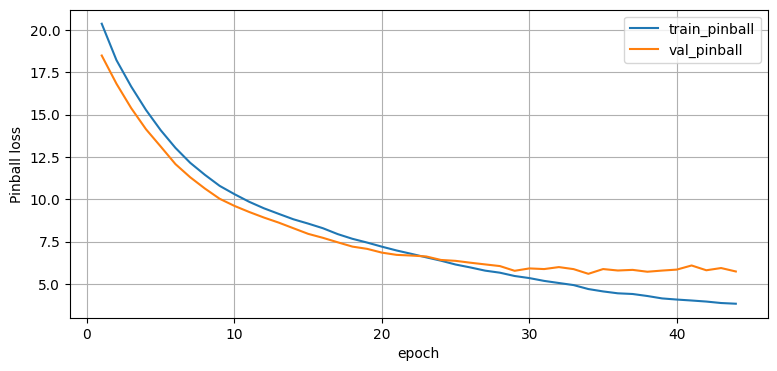

In [7]:
set_seed()
model = RULLSTM(len(FEATURE_COLUMNS), HIDDEN_SIZE).to(DEVICE)
loss_fn = QuantileLoss(QUANTILE)
optimizer = torch.optim.AdamW(
    model.parameters(), lr=LEARNING_RATE, weight_decay=1e-4
)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode='min', factor=0.5, patience=3, min_lr=1e-5
)

best_state = None
best_val_loss = float('inf')
best_epoch = 0
epochs_without_improvement = 0
history = []

for epoch in range(1, MAX_EPOCHS + 1):
    train_loss = run_epoch(model, train_loader, loss_fn, optimizer)
    val_loss = run_epoch(model, val_loader, loss_fn)
    scheduler.step(val_loss)
    history.append({
        'epoch': epoch, 'train_pinball': train_loss, 'val_pinball': val_loss
    })

    if val_loss < best_val_loss - 1e-4:
        best_val_loss = val_loss
        best_epoch = epoch
        best_state = copy.deepcopy(model.state_dict())
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1

    print(
        f'Epoch {epoch:03d} | train={train_loss:.4f} | '
        f'val={val_loss:.4f} | best={best_val_loss:.4f}'
    )
    if epochs_without_improvement >= PATIENCE:
        print('Early stopping. Best epoch:', best_epoch)
        break

model.load_state_dict(best_state)
history_df = pd.DataFrame(history)
history_df.plot(
    x='epoch', y=['train_pinball', 'val_pinball'], figsize=(9, 4), grid=True
)
plt.ylabel('Pinball loss')
plt.show()



## 7. Refit final model on all training engines

In [8]:
detector_final, scaler_final = fit_preprocessor(train_full)
train_full_scaled = transform_data(train_full, detector_final, scaler_final)
final_dataset = PartialHistoryDataset(
    train_full_scaled, FEATURE_COLUMNS, WINDOW_SIZE
)
final_loader = make_loader(final_dataset, shuffle=True, seed=SEED)

set_seed()
final_model = RULLSTM(len(FEATURE_COLUMNS), HIDDEN_SIZE).to(DEVICE)
final_optimizer = torch.optim.AdamW(
    final_model.parameters(), lr=LEARNING_RATE, weight_decay=1e-4
)

for epoch in range(1, best_epoch + 1):
    loss = run_epoch(final_model, final_loader, loss_fn, final_optimizer)
    print(f'Refit {epoch:03d}/{best_epoch:03d} | pinball={loss:.4f}')

final_model.eval()


Refit 001/034 | pinball=19.9635
Refit 002/034 | pinball=17.5125
Refit 003/034 | pinball=15.6925
Refit 004/034 | pinball=14.1269
Refit 005/034 | pinball=12.8506
Refit 006/034 | pinball=11.8765
Refit 007/034 | pinball=11.0243
Refit 008/034 | pinball=10.3308
Refit 009/034 | pinball=9.7542
Refit 010/034 | pinball=9.2718
Refit 011/034 | pinball=8.8188
Refit 012/034 | pinball=8.3651
Refit 013/034 | pinball=7.9934
Refit 014/034 | pinball=7.6919
Refit 015/034 | pinball=7.3475
Refit 016/034 | pinball=7.0915
Refit 017/034 | pinball=6.8862
Refit 018/034 | pinball=6.6306
Refit 019/034 | pinball=6.4642
Refit 020/034 | pinball=6.2511
Refit 021/034 | pinball=6.1068
Refit 022/034 | pinball=5.8815
Refit 023/034 | pinball=5.6994
Refit 024/034 | pinball=5.4961
Refit 025/034 | pinball=5.3187
Refit 026/034 | pinball=5.1353
Refit 027/034 | pinball=5.0097
Refit 028/034 | pinball=4.7516
Refit 029/034 | pinball=4.5897
Refit 030/034 | pinball=4.3785
Refit 031/034 | pinball=4.2022
Refit 032/034 | pinball=4.1572


RULLSTM(
  (lstm): LSTM(27, 64, batch_first=True)
  (fc): Linear(in_features=64, out_features=1, bias=True)
)

## 8. Official FD001 evaluation and NASA asymmetric score

NASA Score: `error = prediction - true`. Overestimation використовує `exp(error / 10)`, underestimation — `exp(-error / 13)`. Менше — краще.

In [9]:
def nasa_score(y_true, y_pred):
    error = np.asarray(y_pred, dtype=np.float64) - np.asarray(y_true, dtype=np.float64)
    return float(np.sum(np.where(
        error < 0,
        np.exp(-error / 13.0) - 1.0,
        np.exp(error / 10.0) - 1.0,
    )))


def evaluate(y_true, y_pred, cap=None):
    y_true = np.asarray(y_true, dtype=np.float64)
    y_pred = np.asarray(y_pred, dtype=np.float64)
    if cap is not None:
        y_true = np.minimum(y_true, cap)
        y_pred = np.minimum(y_pred, cap)
    error = y_pred - y_true
    over = error > 0
    return {
        'MAE': mean_absolute_error(y_true, y_pred),
        'RMSE': mean_squared_error(y_true, y_pred) ** 0.5,
        'R2': r2_score(y_true, y_pred),
        'NASA Score': nasa_score(y_true, y_pred),
        'Overestimation rate': over.mean(),
        'Mean overestimation': error[over].mean() if over.any() else 0.0,
        'Max overestimation': error[over].max() if over.any() else 0.0,
        'Conservative coverage': (error <= 0).mean(),
        'Mean bias': error.mean(),
    }


test_scaled = transform_data(test_full, detector_final, scaler_final)
test_unit_ids, X_test = make_last_windows(
    test_scaled, FEATURE_COLUMNS, WINDOW_SIZE
)
expected_ids = np.arange(1, len(y_test_true) + 1)
if not np.array_equal(test_unit_ids, expected_ids):
    raise ValueError('Test engine order does not match RUL_FD001.txt.')

with torch.inference_mode():
    y_test_pred = final_model(
        torch.from_numpy(X_test).to(DEVICE)
    ).cpu().numpy()
y_test_pred = np.clip(y_test_pred, 0, None)

raw_metrics = evaluate(y_test_true, y_test_pred)
capped_metrics = evaluate(
    y_test_true, y_test_pred, cap=RUL_CAP_FOR_REPORT
)
report = pd.DataFrame({
    'Raw RUL': raw_metrics,
    f'RUL capped at {RUL_CAP_FOR_REPORT}': capped_metrics,
}).T
display(report)
print('NASA Score: lower is better.')
print('P20 target coverage is approximately 0.80.')


,MAE,RMSE,R2,NASA Score,Overestimation rate,Mean overestimation,Max overestimation,Conservative coverage,Mean bias
Raw RUL,9.912587,15.060340,0.868656,466.106718,0.46,13.410487,40.250961,0.54,2.425061
RUL capped at 125,7.258501,11.039788,0.924105,175.492725,0.43,8.862459,32.000000,0.57,0.363214


NASA Score: lower is better.
P20 target coverage is approximately 0.80.


### Реєстрація фінальних моделей у MLflow

Цей крок виконується після одноразової оцінки, щоб у MLflow збереглися саме фінальні ваги, а не проміжна модель із model-selection.


In [ ]:
mlflow_run_id = log_torch_model_to_mlflow(
    model=final_model,
    run_name="FINAL | conservative_lstm_q20_w80",
    params={
        "dataset": "NASA C-MAPSS FD001",
        "architecture": "RULLSTM",
        "quantile": QUANTILE,
        "window_size": WINDOW_SIZE,
        "hidden_size": HIDDEN_SIZE,
        "selected_epochs": best_epoch,
        "partial_histories": True,
        "seed": SEED,
    },
    metrics={f"raw_{key}": value for key, value in raw_metrics.items()},
    model_name="conservative_lstm_q20",
)


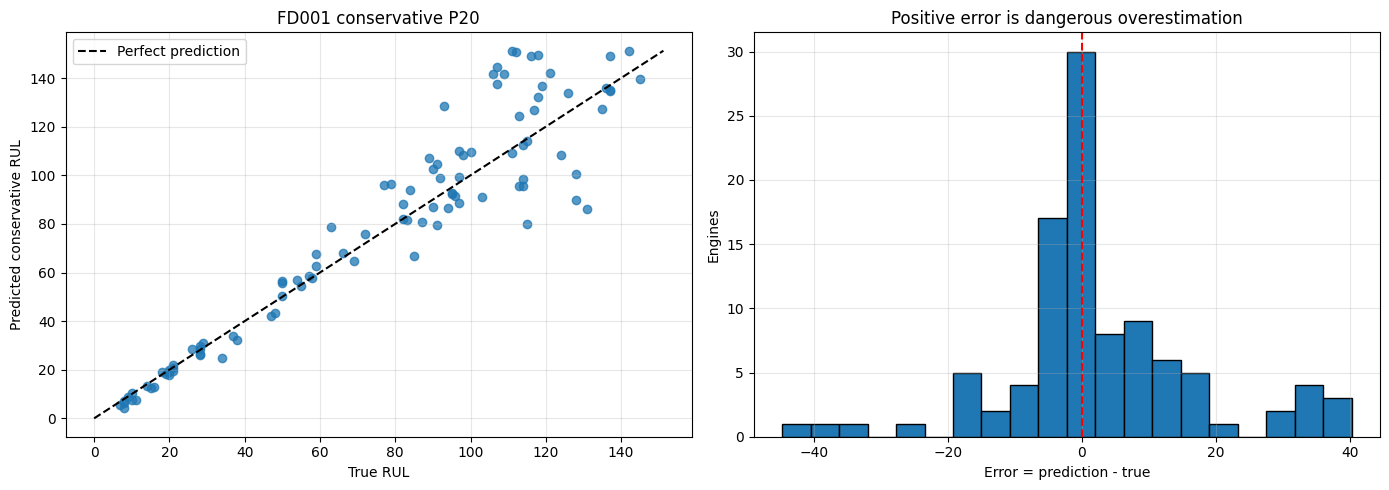

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
limit = max(float(y_test_true.max()), float(y_test_pred.max()))
axes[0].scatter(y_test_true, y_test_pred, alpha=0.75)
axes[0].plot([0, limit], [0, limit], 'k--', label='Perfect prediction')
axes[0].set(
    xlabel='True RUL', ylabel='Predicted conservative RUL',
    title='FD001 conservative P20',
)
axes[0].legend()
axes[0].grid(alpha=0.3)

errors = y_test_pred - y_test_true
axes[1].hist(errors, bins=20, edgecolor='black')
axes[1].axvline(0, color='red', linestyle='--')
axes[1].set(
    xlabel='Error = prediction - true', ylabel='Engines',
    title='Positive error is dangerous overestimation',
)
axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()


## 9. Save model, preprocessing, predictions and ZIP

In [ ]:
MODEL_PATH = OUT_DIR / 'best_lstm_conservative_q20_w80.pt'
SCALER_PATH = OUT_DIR / 'scaler_lstm_conservative_q20_fd001.pkl'
DETECTOR_PATH = OUT_DIR / 'degradation_detector_conservative_q20.json'
METADATA_PATH = OUT_DIR / 'conservative_q20_metadata.json'
PREDICTIONS_PATH = OUT_DIR / 'conservative_q20_fd001_predictions.csv'
HISTORY_PATH = OUT_DIR / 'conservative_q20_training_history.csv'
ZIP_PATH = OUT_DIR / 'conservative_q20_artifacts.zip'

state_dict = {
    key: value.detach().cpu()
    for key, value in final_model.state_dict().items()
}
torch.save(state_dict, MODEL_PATH)
joblib.dump(scaler_final, SCALER_PATH)
DETECTOR_PATH.write_text(
    json.dumps(detector_final.to_dict(), indent=2, ensure_ascii=False),
    encoding='utf-8',
)

metadata = {
    'model_name': 'lstm_conservative_q20',
    'architecture': 'RULLSTM',
    'dataset': 'NASA C-MAPSS FD001',
    'quantile': QUANTILE,
    'window_size': WINDOW_SIZE,
    'input_size': len(FEATURE_COLUMNS),
    'hidden_size': HIDDEN_SIZE,
    'features': FEATURE_COLUMNS,
    'trained_on_partial_histories': True,
    'minimum_history_cycles': 1,
    'selected_epochs': best_epoch,
    'seed': SEED,
    'raw_metrics': {key: float(value) for key, value in raw_metrics.items()},
    'capped_metrics': {key: float(value) for key, value in capped_metrics.items()},
}
METADATA_PATH.write_text(
    json.dumps(metadata, indent=2, ensure_ascii=False), encoding='utf-8'
)

pd.DataFrame({
    'unit_id': test_unit_ids,
    'true_rul': y_test_true,
    'predicted_rul_q20': y_test_pred,
    'error': y_test_pred - y_test_true,
}).to_csv(PREDICTIONS_PATH, index=False)
history_df.to_csv(HISTORY_PATH, index=False)

artifact_paths = [
    MODEL_PATH, SCALER_PATH, DETECTOR_PATH, METADATA_PATH,
    PREDICTIONS_PATH, HISTORY_PATH,
]
with zipfile.ZipFile(ZIP_PATH, 'w', compression=zipfile.ZIP_DEFLATED) as archive:
    for path in artifact_paths:
        archive.write(path, arcname=path.name)

for path in artifact_paths + [ZIP_PATH]:
    print(path, f'({path.stat().st_size / 1024:.1f} KiB)')
